# Iris Flower Classification

## 1. Project Overview

The objective of this project is to develop a Machine Learning
classification model that predicts the species of an Iris flower
based on its physical measurements.

The model will classify flowers into three species:

- Iris Setosa
- Iris Versicolor
- Iris Virginica

## 2. Dataset Information

This project uses the built-in Iris dataset provided by
Scikit-learn.

The dataset contains four numerical features:

1. Sepal Length
2. Sepal Width
3. Petal Length
4. Petal Width

The target variable represents the species of the flower.

## 3. Project Workflow

1. Dataset Loading
2. Exploratory Data Analysis (EDA)
3. Data Visualization
4. Feature Analysis
5. Train-Test Split
6. Model Training
7. Model Evaluation
8. Model Comparison and Conclusion

## 4. Technologies Used

- Python
- Pandas
- Scikit-learn
- Matplotlib
- Seaborn
- Jupyter Notebook

In [26]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [27]:
# Load the built-in Iris dataset

iris = load_iris()

# Create a Pandas DataFrame
df = pd.DataFrame(
    data=iris.data,
    columns=iris.feature_names
)

# Add the target species
df['species'] = pd.Categorical.from_codes(
    iris.target,
    iris.target_names
)

# Display the first five records
display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [28]:
# Check dataset dimensions

print("Dataset loaded successfully!")
print(f"Total records: {df.shape[0]}")
print(f"Total columns: {df.shape[1]}")
print(f"Features: {len(iris.feature_names)}")
print(f"Target classes: {len(iris.target_names)}")

Dataset loaded successfully!
Total records: 150
Total columns: 5
Features: 4
Target classes: 3


## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the
structure, quality and statistical characteristics of the dataset.

### 5.1 Dataset Information

In [29]:
# Display dataset information

print("Dataset Information:")
print("-" * 50)

df.info()

Dataset Information:
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   sepal length (cm)  150 non-null    float64 
 1   sepal width (cm)   150 non-null    float64 
 2   petal length (cm)  150 non-null    float64 
 3   petal width (cm)   150 non-null    float64 
 4   species            150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.0 KB


In [30]:
# Check missing values in each column

print("Missing Values:")
print("-" * 50)

print(df.isnull().sum())

# Calculate total missing values
total_missing = df.isnull().sum().sum()

print("\nTotal Missing Values:", total_missing)

Missing Values:
--------------------------------------------------
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Total Missing Values: 0


In [31]:
# Generate descriptive statistics

print("Descriptive Statistics:")
print("-" * 50)

display(df.describe())

Descriptive Statistics:
--------------------------------------------------


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### 5.2 Observations from Dataset Inspection

**Dataset Structure:**

- The dataset contains 150 observations and 5 columns.
- Four columns contain numerical measurements, while the species column is categorical.
- All numerical features use the `float64` data type.
- The target variable uses the categorical data type.

**Missing Value Analysis:**

- No missing values were detected in any column.
- All 150 observations contain complete information.
- No missing-value treatment is required.

**Descriptive Statistics:**

- Sepal length has an average value of approximately 5.84 cm.
- Sepal width has the lowest standard deviation of approximately 0.44 cm.
- Petal length has the highest standard deviation of approximately 1.77 cm.
- Petal width also demonstrates considerable variation.

**Initial Finding:**

Petal length and petal width appear promising for distinguishing Iris species because of their comparatively higher variability. Further visual analysis will help determine their discriminative power.

Species Distribution:
--------------------------------------------------


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

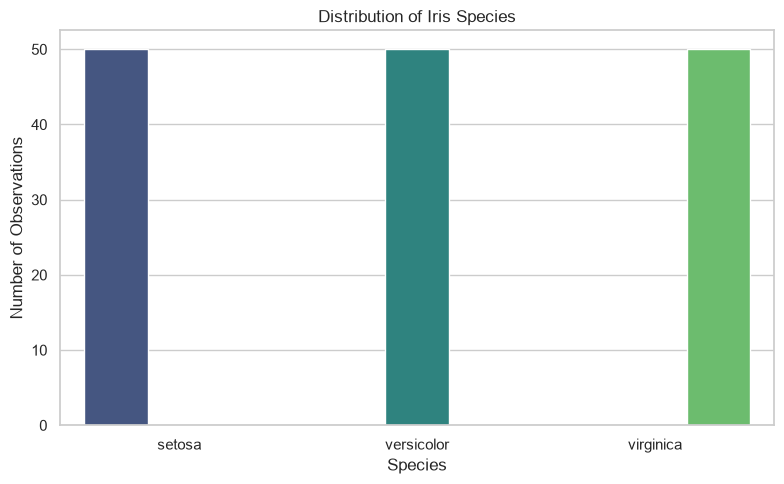

In [32]:
# Count observations for each species

print("Species Distribution:")
print("-" * 50)

display(df['species'].value_counts())

# Visualize species distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='species',
    hue='species',
    palette='viridis',
    legend=False
)

plt.title('Distribution of Iris Species')
plt.xlabel('Species')
plt.ylabel('Number of Observations')
plt.tight_layout()
plt.show()

### 6.1 Pairplot Analysis

A pairplot is used to visualise relationships between numerical
features and identify patterns that distinguish different
Iris species.

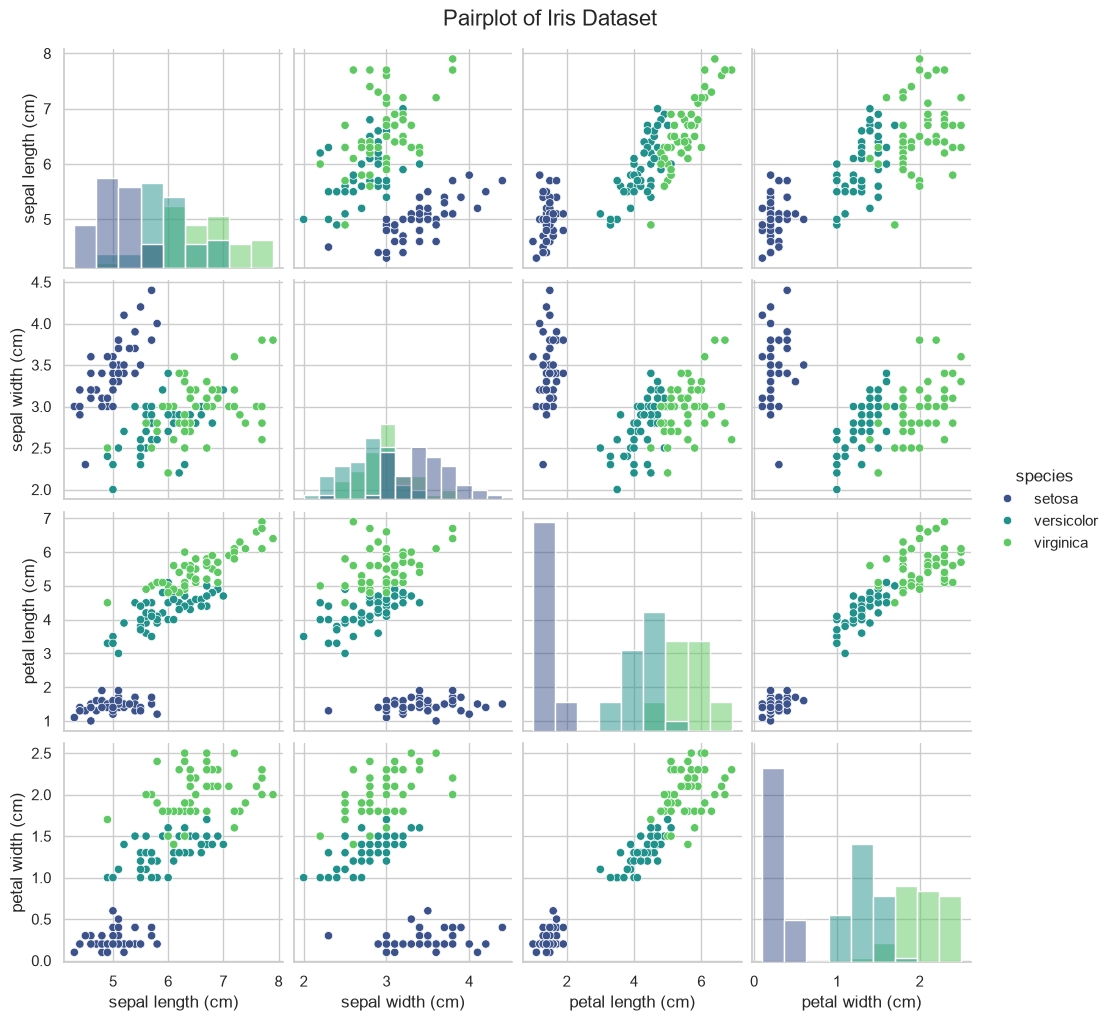

In [33]:
# Pairplot of Iris dataset

sns.pairplot(
    df,
    hue='species',
    palette='viridis',
    diag_kind='hist'
)

plt.suptitle(
    'Pairplot of Iris Dataset',
    y=1.02,
    fontsize=16
)

plt.show()

### 6.2 Box Plot Analysis

Box plots are used to understand the distribution of each
numerical feature across the three Iris species.

They help identify differences in median values, variability
and potential outliers.

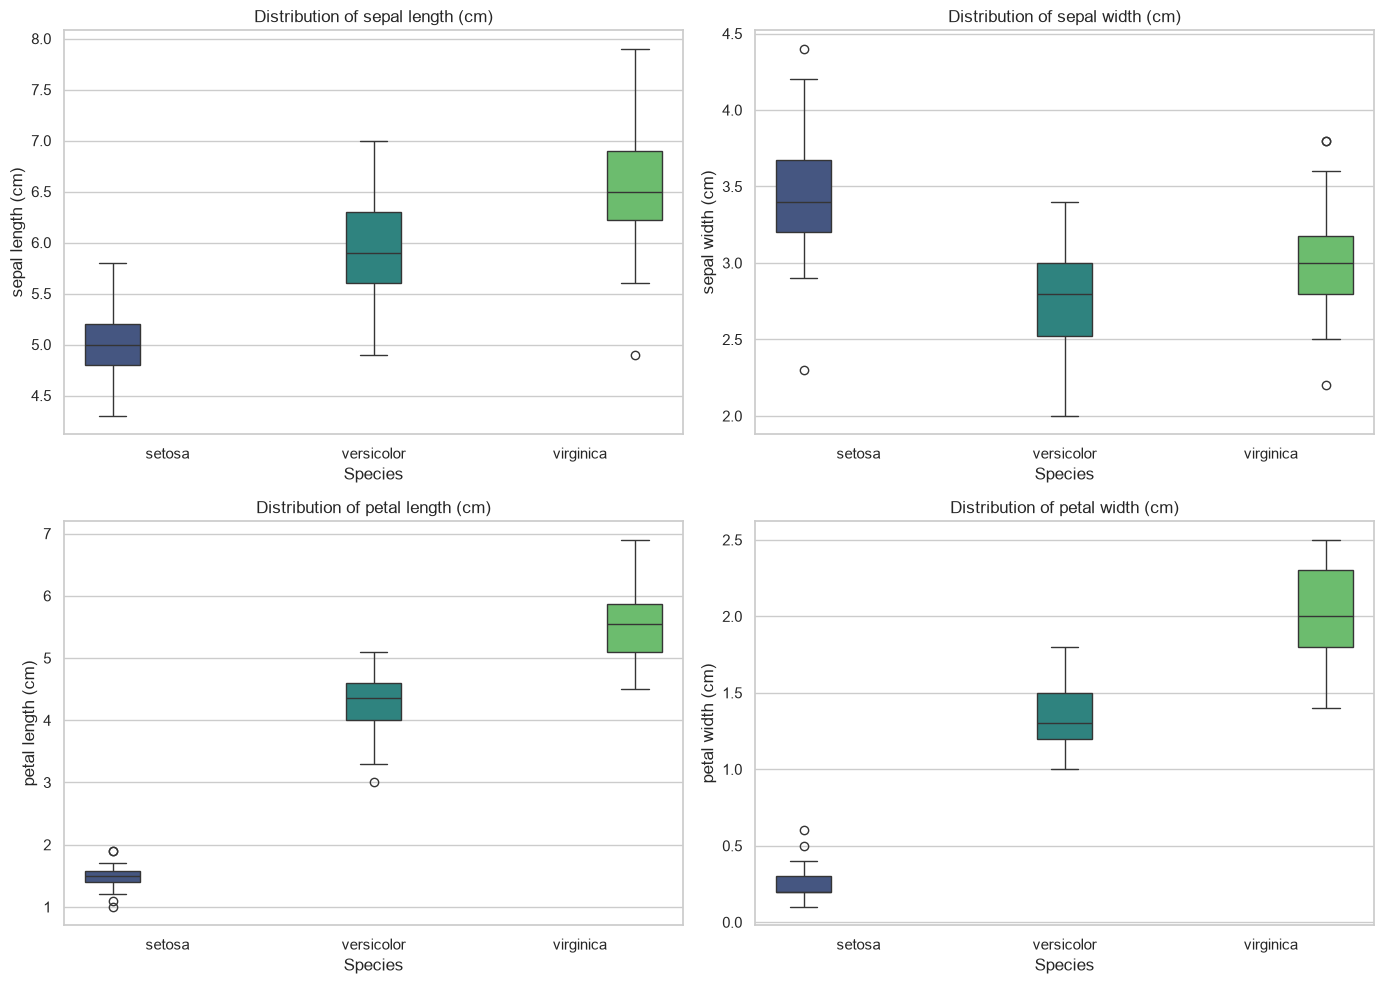

In [34]:
# Box plots for all four numerical features

features = iris.feature_names

plt.figure(figsize=(14, 10))

for i, feature in enumerate(features, 1):

    plt.subplot(2, 2, i)

    sns.boxplot(
        data=df,
        x='species',
        y=feature,
        hue='species',
        palette='viridis',
        legend=False
    )

    plt.title(f'Distribution of {feature}')
    plt.xlabel('Species')
    plt.ylabel(feature)

plt.tight_layout()
plt.show()

### 6.3 Observations from Data Visualisation

**Pairplot Analysis:**

1. Iris Setosa forms a clearly separated cluster, particularly when examining petal length and petal width.
2. Iris Versicolor generally exhibits intermediate petal measurements.
3. Iris Virginica generally has larger petal measurements than the other two species.
4. Some overlap exists between Versicolor and Virginica.
5. Petal length and petal width demonstrate stronger species separation than sepal length and sepal width.

**Box Plot Analysis:**

1. Sepal length shows differences in median values across species, although the distributions overlap.
2. Sepal width exhibits considerable overlap between the three species.
3. Petal length demonstrates substantial differences in median values across species.
4. Petal width also provides strong separation, especially for Iris Setosa.
5. Several potential outliers are visible in the box plots. These observations will be retained because an outlier does not necessarily represent an incorrect measurement.

**Overall Finding:**

Petal length and petal width appear to be the most discriminative features for classifying Iris species. These features will be particularly important during model training and evaluation.

## 7. Feature Selection and Analysis

Feature selection involves identifying the input variables
that provide the most useful information for predicting
the target variable.

Based on the pairplot and box plot visualisations,
petal length and petal width appear to be the most
discriminative features.

In [35]:
# Compare average feature measurements across species

feature_comparison = df.groupby(
    'species',
    observed=True
)[iris.feature_names].mean()

display(feature_comparison)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


### 7.1 Feature Selection Findings

The average measurements across the three Iris species reveal important differences in their physical characteristics.

**Petal Length:**

- Setosa has an average petal length of 1.462 cm.
- Versicolor has an average petal length of 4.260 cm.
- Virginica has an average petal length of 5.552 cm.

**Petal Width:**

- Setosa has an average petal width of 0.246 cm.
- Versicolor has an average petal width of 1.326 cm.
- Virginica has an average petal width of 2.026 cm.

**Feature Selection Conclusion:**

Petal length and petal width appear to be the most discriminative features because their average values show substantial differences across the three species.

Sepal length also provides useful information, whereas sepal width appears comparatively less discriminative.

Therefore, all four features will initially be retained for model training, with particular attention given to the importance of petal measurements.

## 8. Train-Test Split

The dataset is divided into training and testing subsets.

- 80% of the data is used for model training.
- 20% of the data is reserved for model evaluation.

Stratified sampling is used to preserve the proportion
of each species in both subsets.

In [36]:
# Import train_test_split

from sklearn.model_selection import train_test_split

# Separate features and target

X = df.drop('species', axis=1)
y = df['species']

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset dimensions

print("Training and Testing Dataset Split")
print("-" * 45)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training and Testing Dataset Split
---------------------------------------------
Training features: (120, 4)
Testing features: (30, 4)
Training target: (120,)
Testing target: (30,)


In [37]:
# Check species distribution in training and testing sets

print("Training Set Distribution:")
display(y_train.value_counts())

print("\nTesting Set Distribution:")
display(y_test.value_counts())

Training Set Distribution:


species
setosa        40
versicolor    40
virginica     40
Name: count, dtype: int64


Testing Set Distribution:


species
setosa        10
versicolor    10
virginica     10
Name: count, dtype: int64

## 9. Model Training

Four classification algorithms are implemented and compared:

1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Decision Tree
4. Random Forest

Feature scaling is applied to Logistic Regression and KNN
using StandardScaler.

Decision Tree and Random Forest use the original features
because tree-based algorithms do not require standardisation.

In [38]:
# Import classification algorithms and preprocessing tools

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

print("Classification algorithms imported successfully!")

Classification algorithms imported successfully!


In [39]:
# Define classification models

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000))
    ]),

    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

print("Models defined successfully!")

Models defined successfully!


In [40]:
# Train all classification models

for name, model in models.items():

    model.fit(X_train, y_train)

    print(f"{name}: Training completed")

print("\nAll models trained successfully!")

Logistic Regression: Training completed
K-Nearest Neighbors: Training completed
Decision Tree: Training completed
Random Forest: Training completed

All models trained successfully!


## 10. Model Evaluation

The trained classification models are evaluated using
the testing dataset.

The following evaluation metrics are used:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix
- Classification Report

In [41]:
# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [42]:
# Evaluate all trained models

results = []

for name, model in models.items():

    # Generate predictions
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, average='weighted', zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, average='weighted', zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, average='weighted', zero_division=0
    )

    # Store results
    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

# Create comparison DataFrame
results_df = pd.DataFrame(results)

# Display results
display(
    results_df.sort_values(
        by='Accuracy',
        ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333
1,K-Nearest Neighbors,0.933333,0.944444,0.933333,0.932660
2,Decision Tree,0.933333,0.933333,0.933333,0.933333
3,Random Forest,0.900000,0.902357,0.900000,0.899749


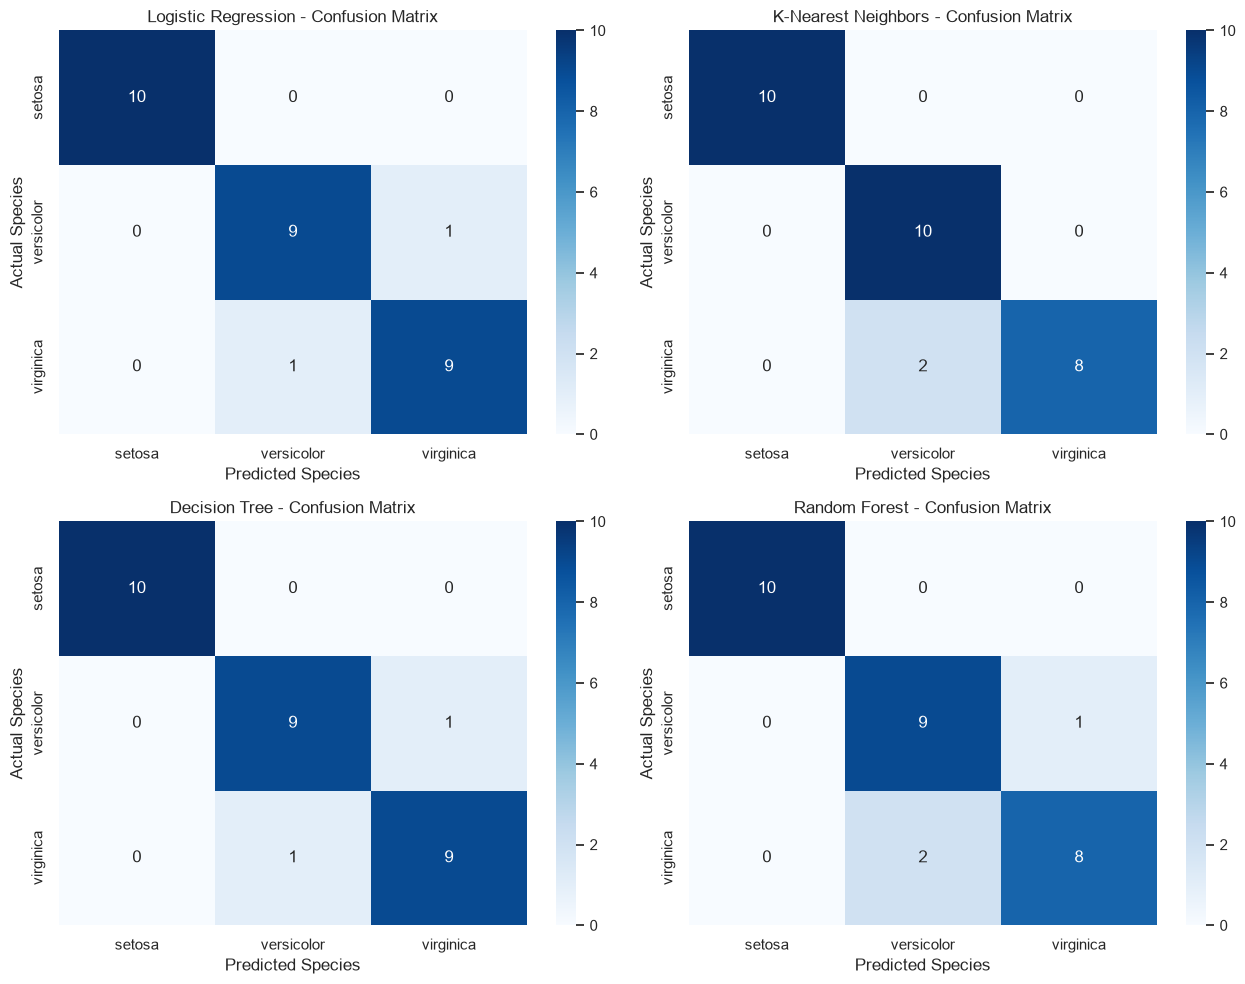

In [43]:
# Generate confusion matrices for all models

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes = axes.flatten()

for ax, (name, model) in zip(axes, models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=iris.target_names
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=iris.target_names,
        yticklabels=iris.target_names,
        ax=ax
    )

    ax.set_title(f'{name} - Confusion Matrix')
    ax.set_xlabel('Predicted Species')
    ax.set_ylabel('Actual Species')

plt.tight_layout()
plt.show()

In [44]:
# Classification reports for all models

for name, model in models.items():

    print("=" * 65)
    print(f"Classification Report: {name}")
    print("=" * 65)

    y_pred = model.predict(X_test)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=iris.target_names,
            zero_division=0
        )
    )

Classification Report: Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Classification Report: K-Nearest Neighbors
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

Classification Report: Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  vers

### 10.1 Model Evaluation Findings

Four classification algorithms were evaluated using the testing dataset.

**Logistic Regression:**
- Accuracy: 93.33%
- Weighted Precision: 93.33%
- Weighted Recall: 93.33%
- Weighted F1-score: 93.33%

**K-Nearest Neighbors:**
- Accuracy: 93.33%
- Weighted Precision: 94.44%
- Weighted Recall: 93.33%
- Weighted F1-score: 93.27%

**Decision Tree:**
- Accuracy: 93.33%
- Weighted Precision: 93.33%
- Weighted Recall: 93.33%
- Weighted F1-score: 93.33%

**Random Forest:**
- Accuracy: 90.00%
- Weighted Precision: 90.24%
- Weighted Recall: 90.00%
- Weighted F1-score: 89.97%

**Confusion Matrix Observations:**

- All four models correctly classified all 10 Setosa observations.
- Logistic Regression and Decision Tree each correctly classified 9 Versicolor and 9 Virginica observations.
- KNN correctly classified all Versicolor observations but misclassified 2 Virginica observations.
- Random Forest correctly classified 9 Versicolor and 8 Virginica observations.

### 10.2 Best-Performing Model

Logistic Regression and Decision Tree achieved the highest weighted F1-score of 93.33%, along with an accuracy of 93.33%.

Both models are therefore considered joint top performers on this test split.

Logistic Regression is selected as the primary model for the final demonstration because it achieves the same overall performance as Decision Tree using a relatively simple classification approach.

KNN is also competitive, achieving the highest weighted precision of 94.44%.

Random Forest achieved the lowest accuracy among the four evaluated models, at 90.00%.

**Conclusion:** Logistic Regression is selected as the primary model, with Decision Tree recognised as an equally performing alternative on the current test dataset.

In [45]:
# Identify the best-performing model using weighted F1-score

best_f1 = results_df['F1-Score'].max()

best_models = results_df[
    results_df['F1-Score'] == best_f1
]

print("Best-performing model(s):")
display(best_models)

print(f"\nHighest weighted F1-score: {best_f1:.4f}")

Best-performing model(s):


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333
2,Decision Tree,0.933333,0.933333,0.933333,0.933333



Highest weighted F1-score: 0.9333


## 11. Model Performance Comparison

The performance of the four classification algorithms is
compared using their accuracy scores.

This visualisation helps identify the models that achieved
the highest classification accuracy.

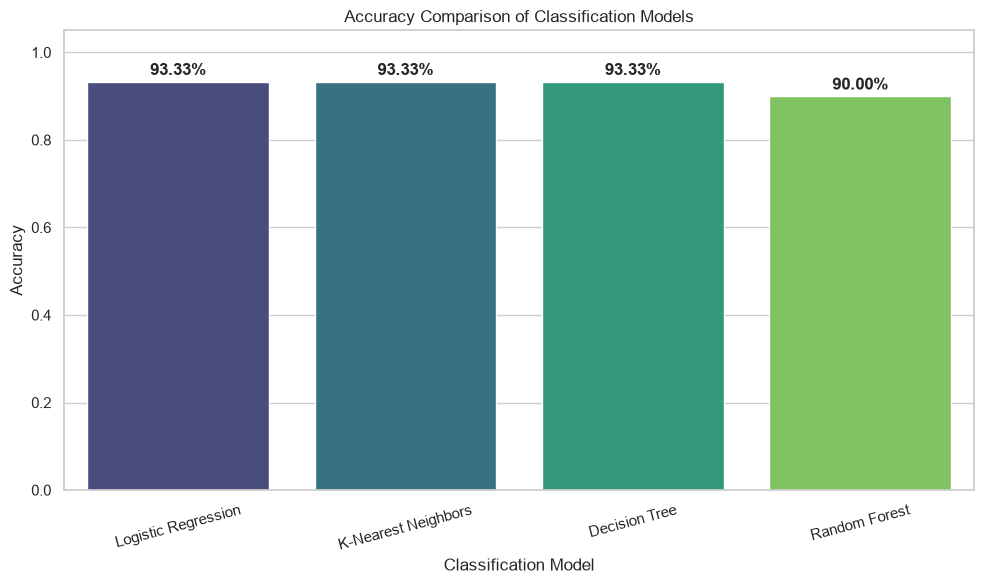

In [46]:
# Visual comparison of model accuracy

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title('Accuracy Comparison of Classification Models')
plt.xlabel('Classification Model')
plt.ylabel('Accuracy')
plt.ylim(0, 1.05)

# Display accuracy values above bars
for i, value in enumerate(results_df['Accuracy']):
    plt.text(
        i,
        value + 0.015,
        f'{value:.2%}',
        ha='center',
        fontweight='bold'
    )

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

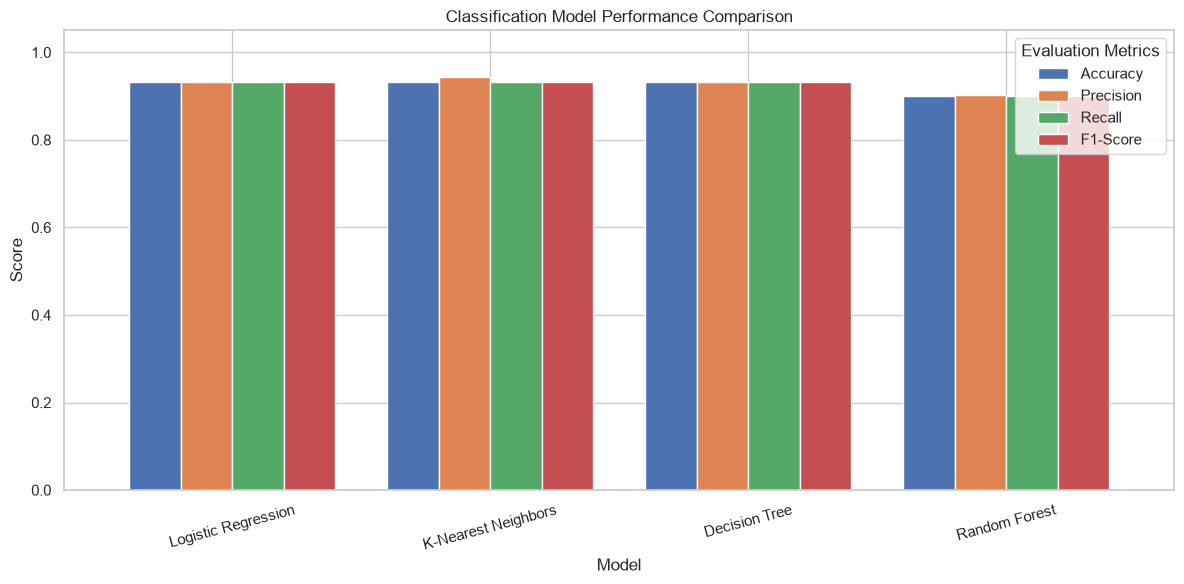

In [47]:
# Compare all evaluation metrics

metrics_df = results_df.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1-Score']
]

metrics_df.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title('Classification Model Performance Comparison')
plt.xlabel('Model')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(title='Evaluation Metrics')
plt.tight_layout()
plt.show()

## 12. Feature Importance Analysis

Feature importance analysis helps us understand how
different input variables contribute to classification.

For Logistic Regression, feature coefficients are examined
to understand the influence of each feature on the
predicted species.

Since Logistic Regression is a multiclass classifier,
each species has its own set of coefficients.

In [48]:
# Extract Logistic Regression coefficients

logistic_model = models['Logistic Regression']

classifier = logistic_model.named_steps['classifier']

coefficients = classifier.coef_

feature_names = X.columns

coefficient_df = pd.DataFrame(
    coefficients,
    columns=feature_names,
    index=classifier.classes_
)

print("Logistic Regression Coefficients:")
display(coefficient_df)

Logistic Regression Coefficients:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
setosa,-1.088945,1.024208,-1.799056,-1.686228
versicolor,0.536337,-0.360487,-0.204074,-0.807957
virginica,0.552608,-0.663721,2.003130,2.494185


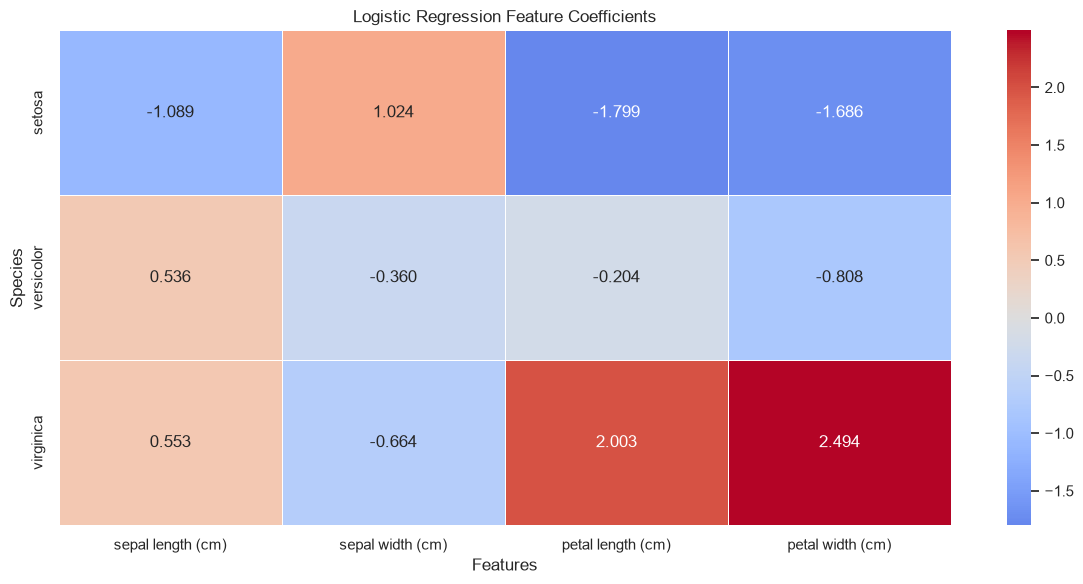

In [49]:
# Visualise Logistic Regression coefficients

plt.figure(figsize=(12, 6))

sns.heatmap(
    coefficient_df,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Logistic Regression Feature Coefficients')
plt.xlabel('Features')
plt.ylabel('Species')

plt.tight_layout()
plt.show()

### 12.1 Feature Coefficient Analysis

The Logistic Regression coefficient analysis provides insight into how the four input features influence the classification of each Iris species.

**Setosa:**
- Petal length (-1.799) and petal width (-1.686) have strong negative coefficients.
- These measurements contribute to distinguishing Setosa from the other species.

**Versicolor:**
- Sepal length has a positive coefficient of 0.536.
- Petal length and petal width have negative coefficients.

**Virginica:**
- Petal length (2.003) and petal width (2.494) have strong positive coefficients.
- Petal width has the largest absolute coefficient for this class.

**Overall Finding:**

Petal length and petal width play important roles in the classification process. This supports the earlier observations from the pairplot and box plots.

The coefficient values represent model weights and should not be interpreted as percentages of feature importance.

# 13. Conclusion

The Iris Flower Classification project successfully demonstrates how machine learning algorithms can classify Iris flowers into three species: Setosa, Versicolor, and Virginica.

The project involved loading the Iris dataset from Scikit-learn, performing exploratory data analysis, visualising feature distributions, discussing feature selection, and training multiple classification algorithms.

Four machine learning algorithms were implemented:

1. Logistic Regression
2. K-Nearest Neighbors
3. Decision Tree
4. Random Forest

The models were evaluated using accuracy, precision, recall, F1-score, confusion matrices, and classification reports.

**Key Findings:**

- The dataset contains 150 observations with no missing values.
- Petal length and petal width provide strong species separation.
- Logistic Regression, KNN, and Decision Tree achieved 93.33% accuracy.
- Random Forest achieved 90.00% accuracy.
- Logistic Regression and Decision Tree achieved the highest weighted F1-score of 93.33%.
- Setosa was classified correctly in all 10 test observations by every model.

**Final Model Selection:**

Logistic Regression was selected as the primary model because it achieved 93.33% accuracy and a weighted F1-score of 93.33%, while offering a relatively simple classification approach.

**Learning Outcomes:**

This project provided practical experience in exploratory data analysis, data visualisation, feature analysis, train-test splitting, classification algorithms, and model evaluation using Python and Scikit-learn.

Overall, the project demonstrates that machine learning can effectively classify Iris flower species using their physical measurements.